[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Joz84/cours_ml_ia/blob/main/tp/visualisation/TP3_visualisation_CORRIGE.ipynb)

**CORRIGÉ**

# TP 3 · Visualiser : le verbe de la question choisit le graphique


UE 5.7 « Data Science et IA » · Licence STES · Université de la Polynésie française

Au TP 2, vous avez écrit des constats chiffrés. Il faut maintenant les **montrer**. Un graphique n'est pas une décoration : il répond à une question. Dans ce TP, vous utilisez une **boîte à outils** qui contient une fonction par graphique standard. Elle applique d'elle-même les règles d'un bon graphique : votre travail est de **choisir le bon graphique** et d'**écrire le message**.

- **Durée :** environ 1 h 30.
- **En binôme**, dans **Google Colab**. Vous n'avez rien à installer : une cellule télécharge la boîte à outils.
- **Méthode :** ouvrez le carnet avec le bouton « Ouvrir dans Colab », ou copiez chaque cellule de code de cette page dans Colab, **dans l'ordre**.
- **Vous ne modifiez que la cellule RÉGLAGES** et les cellules « À compléter » des questions.
- **Si une cellule plante**, copiez-la avec le message d'erreur dans ChatGPT ou Claude. Les fonctions de la boîte à outils expliquent elles-mêmes la plupart des erreurs, par exemple une colonne mal orthographiée.

> **Pour réutiliser ce carnet sur votre propre jeu de données :** changez la cellule RÉGLAGES (le fichier, le séparateur, la colonne de date, la source), puis exécutez dans l'ordre. Les fonctions de la boîte à outils marchent sur n'importe quel tableau : il suffit de leur donner les noms de vos colonnes. La boîte à outils s'utilise aussi seule, dans n'importe quel carnet : voir sa première cellule.

## Une question solide, un bon graphique

**Une question solide a trois ingrédients** : **quoi ?** (la mesure), **selon quoi ?** (la catégorie, le temps ou une autre mesure), **où et quand ?** (le périmètre). Par exemple : « Quelle **pluie totale** (quoi) a reçu **chaque station** (selon quoi) **à Tahiti en 2024** (où et quand) ? »

**Le verbe de la question choisit le graphique** :

| Le verbe de la question | Le graphique | La fonction de la boîte à outils |
|---|---|---|
| **comparer** des catégories | barres | `barres(df, categorie, valeur, agg="mean")` |
| **suivre** dans le temps | courbe | `courbe(df, date, valeur, par=None, pas="M")` |
| **voir la répartition** | histogramme | `histogramme(df, valeur, bins=20)` |
| **chercher un lien** | nuage de points | `nuage(df, x, y, etiquettes=None)` |
| **comparer des groupes en détail** | boîte à moustaches | `boite(df, categorie, valeur)` |
| **montrer une part** d'un tout | camembert (5 parts au plus, avec prudence) | `camembert(df, categorie, valeur=None)` |
| **croiser** deux catégories | barres groupées | `barres_croisees(df, categorie, sous_categorie, valeur)` |
| voir **tous les liens** d'un coup | matrice de corrélations | `correlations(df, colonnes=None)` |

**Un bon graphique en 5 points**, que chaque fonction impose :
1. un **titre qui dit le message** : le paramètre `titre` est obligatoire ;
2. des **axes nommés avec leur unité** : le paramètre `unite` ;
3. **une seule idée** par graphique ;
4. **peu de couleurs** : deux au plus, plus du gris ;
5. **la source et la date**, en bas à droite : le paramètre `source`.

Et une règle de plus : **les barres partent de zéro**.

La boîte à outils est le fichier [`boite_a_outils_graphiques.py`](boite_a_outils_graphiques.py). Chaque fonction y a une explication en français, avec un exemple. Dans Colab, tapez par exemple `help(barres)` pour la lire.

## Le rituel, à chaque étape

> **Je prédis** : je réponds aux questions *avant* d'exécuter la cellule.
> **J'exécute** : je lance la cellule.
> **Je constate** : j'écris deux phrases sur ce que j'observe, et je corrige ma prédiction si besoin.

## Les données

Le tableau propre du TP 1, `releves_meteo_propre.csv` : 1 646 relevés journaliers de 2024, pour 5 stations **fictives** de Tahiti (données simulées).

## Le carnet

### Réglages · La seule cellule à modifier

In [1]:
# ===================== RÉGLAGES : la seule cellule à modifier =====================
URL = "https://raw.githubusercontent.com/Joz84/cours_ml_ia/main/data/clean/releves_meteo_propre.csv"  # le fichier : une URL, ou un chemin dans votre Drive
SEPARATEUR = ","                                   # le caractère entre les colonnes : "," ou ";"
COLONNE_DATE = "date"                              # la colonne des dates, ou None s'il n'y en a pas
SOURCE = "Relevés météo simulés de 5 stations de Tahiti, 2024"   # écrit en bas de chaque graphique
URL_BOITE_A_OUTILS = "https://raw.githubusercontent.com/Joz84/cours_ml_ia/main/tp/visualisation/boite_a_outils_graphiques.py"
# ===================================================================================

### Outils · Charger la boîte à outils et le tableau

La cellule télécharge la boîte à outils, si elle n'est pas déjà là, importe ses 8 fonctions et charge le tableau.

In [2]:
import os
import urllib.request
import pandas as pd

if not os.path.exists("boite_a_outils_graphiques.py"):
    urllib.request.urlretrieve(URL_BOITE_A_OUTILS, "boite_a_outils_graphiques.py")
from boite_a_outils_graphiques import barres, courbe, histogramme, nuage, boite, camembert, barres_croisees, correlations

df = pd.read_csv(URL, sep=SEPARATEUR)
if COLONNE_DATE:
    df[COLONNE_DATE] = pd.to_datetime(df[COLONNE_DATE])
print("Boîte à outils chargée. Tableau :", df.shape)

Boîte à outils chargée. Tableau : (1646, 6)


**Résultat attendu**

```text
Boîte à outils chargée. Tableau : (1646, 6)
```

### Préparer · Une colonne utile pour l'exemple

*Propre à cet exemple.* On ajoute la saison, déduite du mois : la saison des pluies va de novembre à avril. Sur un autre tableau, vous n'en aurez peut-être pas besoin.

In [3]:
df["saison"] = df["date"].dt.month.map(lambda m: "saison des pluies" if m in (11, 12, 1, 2, 3, 4) else "saison fraîche")
df["saison"].value_counts()

saison
saison des pluies    910
saison fraîche       736
Name: count, dtype: int64

**Résultat attendu**

```text
saison
saison des pluies    910
saison fraîche       736
```

## Partie 1 · Les 8 fonctions, en démonstration

Chaque démonstration utilise les **températures**. Les questions de la partie 2 portent sur la **pluie** : à vous de jouer.

### Démo 1 · barres : comparer des catégories

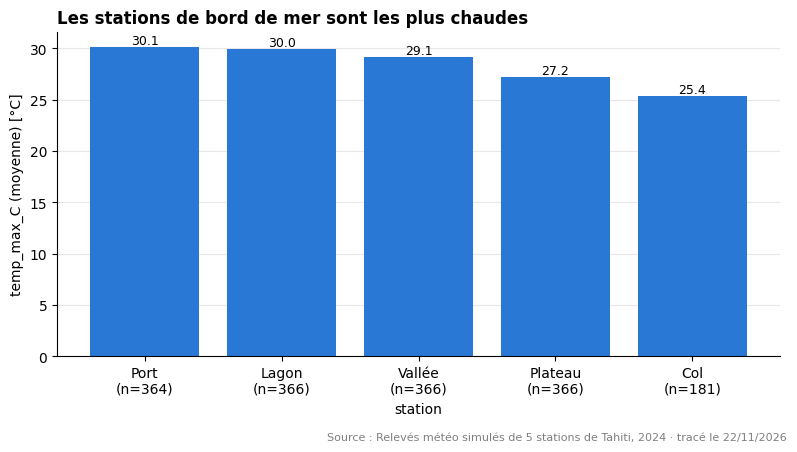

In [4]:
barres(df, "station", "temp_max_C", agg="mean",
       titre="Les stations de bord de mer sont les plus chaudes", unite="°C", source=SOURCE)

**Résultat attendu**

Cinq barres bleues triées, de `Port` (30,1 °C) et `Lagon` (30,0) à `Col` (25,4), avec la valeur au bout de chaque barre et `n` sous chaque station. En bas à droite : la source et la date.

### Démo 2 · courbe : suivre dans le temps

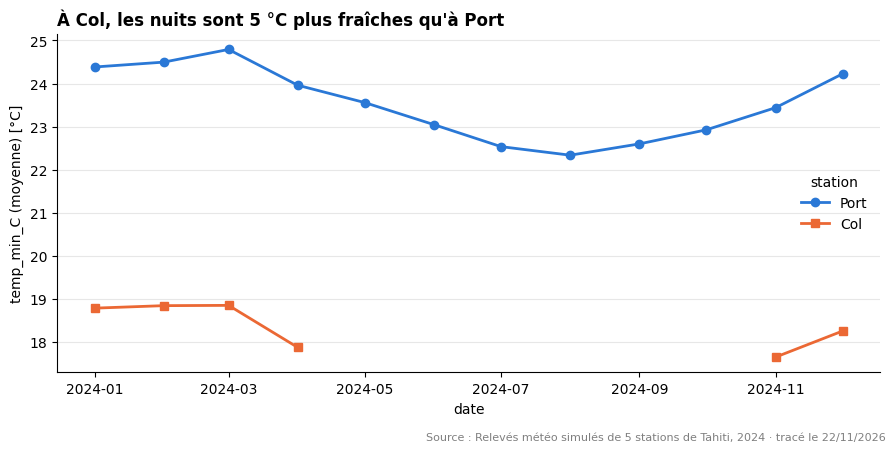

In [5]:
courbe(df, "date", "temp_min_C", par="station", garder=["Port", "Col"], pas="M", agg="mean",
       titre="À Col, les nuits sont 5 °C plus fraîches qu'à Port", unite="°C", source=SOURCE)

**Résultat attendu**

Deux courbes, `Port` en bleu et `Col` en orange : la courbe de `Col` n'existe que de novembre à avril, environ 5 °C sous celle de `Port`.

### Démo 3 · histogramme : voir la répartition

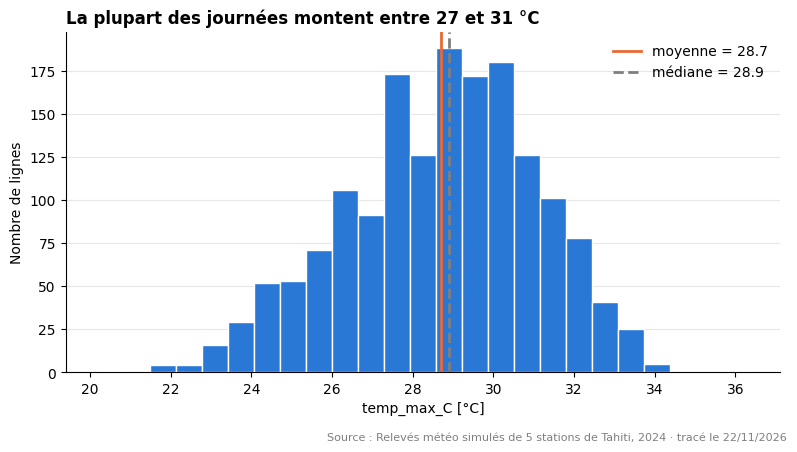

In [6]:
histogramme(df, "temp_max_C", bins=25,
            titre="La plupart des journées montent entre 27 et 31 °C", unite="°C", source=SOURCE)

**Résultat attendu**

Un histogramme en cloche, centré vers 29 °C, avec la moyenne (28,7) en orange et la médiane (28,9) en gris pointillé, presque confondues.

### Démo 4 · nuage : chercher un lien

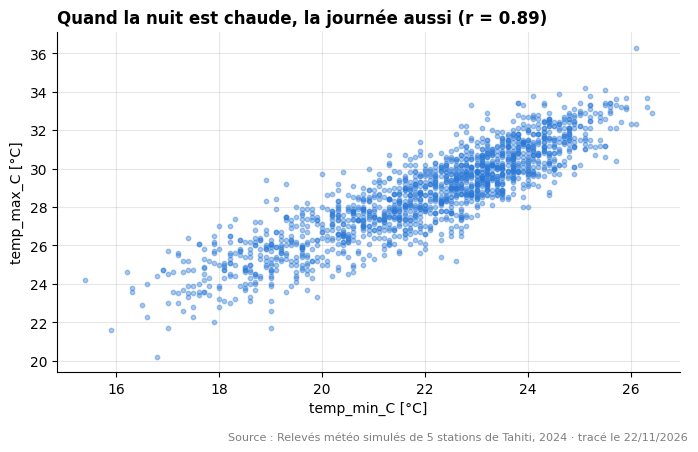

In [7]:
nuage(df, "temp_min_C", "temp_max_C",
      titre="Quand la nuit est chaude, la journée aussi", unite=("°C", "°C"), source=SOURCE)

**Résultat attendu**

Un nuage de points allongé en diagonale, avec « (r = 0.89) » à la fin du titre.

### Démo 5 · boite : comparer des groupes en détail

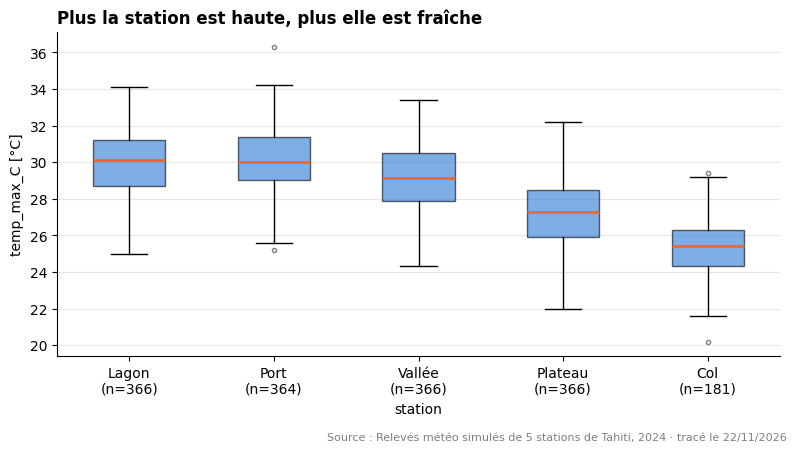

In [8]:
boite(df, "station", "temp_max_C",
      titre="Plus la station est haute, plus elle est fraîche", unite="°C", source=SOURCE)

**Résultat attendu**

Cinq boîtes triées par médiane, de `Port` à `Col`, avec `n` sous chaque station.

### Démo 6 · camembert : montrer une part d'un tout

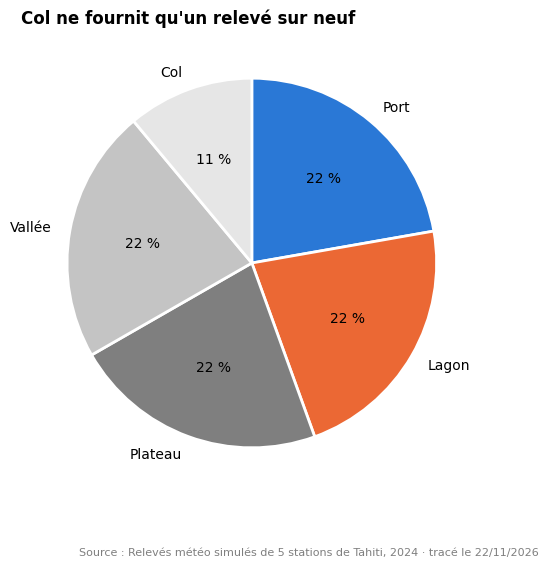

In [9]:
camembert(df, "station", titre="Col ne fournit qu'un relevé sur neuf", source=SOURCE)

**Résultat attendu**

Un camembert à 5 parts : 22 % pour chacune des 4 stations complètes, 11 % pour `Col`.

### Démo 7 · barres_croisees : croiser deux catégories

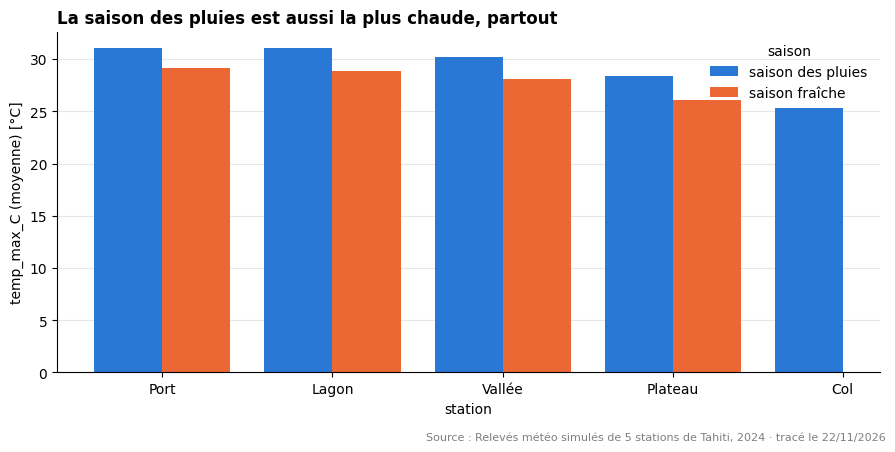

In [10]:
barres_croisees(df, "station", "saison", "temp_max_C", agg="mean",
                titre="La saison des pluies est aussi la plus chaude, partout", unite="°C", source=SOURCE)

**Résultat attendu**

Des barres groupées : bleu pour la saison des pluies, orange pour la saison fraîche. La barre bleue est plus haute partout. `Col` n'a qu'une barre.

### Démo 8 · correlations : voir tous les liens d'un coup

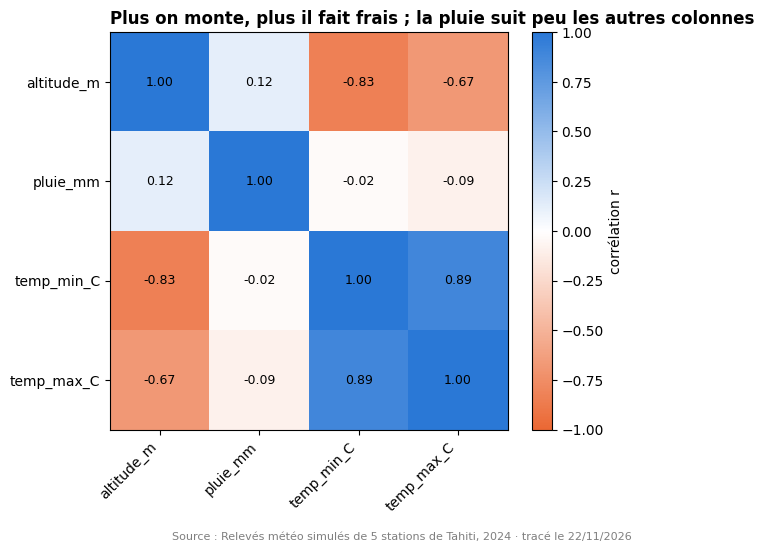

In [11]:
correlations(df, titre="Plus on monte, plus il fait frais ; la pluie suit peu les autres colonnes", source=SOURCE)

**Résultat attendu**

Une matrice 4 × 4 : bleu pour les liens positifs (0,89 entre les deux températures), orange pour les négatifs (-0,83 entre l'altitude et la température minimale), presque blanc pour la pluie.

## Partie 2 · Vos questions

Pour chaque question :
- **(a)** nommez le **verbe** de la question ;
- **(b)** choisissez la **fonction** dans le tableau « verbe → fonction » ;
- **(c)** produisez le **graphique**, en complétant la cellule ;
- **(d)** écrivez le **message** en une phrase. C'est ce message qui devient le `titre` du graphique.

Les trois ingrédients de chaque question sont donnés : **quoi ? selon quoi ? où et quand ?**

### Q1 · Quelle station a reçu le plus de pluie en 2024 ?

> **Je prédis → J'exécute → Je constate**

Quoi ? la pluie **totale** · selon quoi ? la station · où et quand ? 5 stations de Tahiti, 2024.

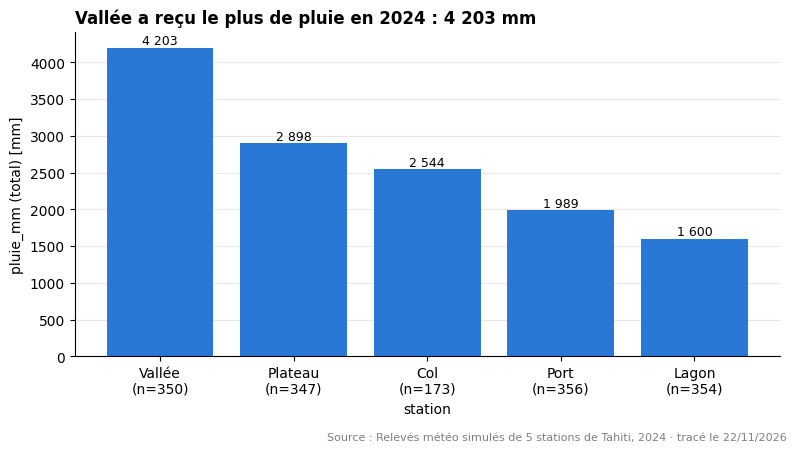

In [12]:
barres(df, "station", "pluie_mm", agg="sum",
       titre="Vallée a reçu le plus de pluie en 2024 : 4 203 mm", unite="mm", source=SOURCE)

**Résultat attendu**

Cinq barres triées : `Vallée` 4 203 mm, `Plateau` 2 898, `Col` 2 544, `Port` 1 989 et `Lagon` 1 600. Sous `Col`, `n=173` : deux fois moins de relevés que les autres.

**Questions**
- (a) le verbe, (b) la fonction, (d) le message. Regardez les `n` sous les barres : la comparaison avec `Col` est-elle juste ?

**Réponse.** (a) **comparer** des catégories ; (b) **`barres`**, avec `agg="sum"` ; (d) « Vallée a reçu le plus de pluie en 2024 : 4 203 mm », plus de 2,6 fois `Lagon` (1 600 mm). Mais regardez les n : `Col` n'a que 173 valeurs, sur 6 mois. Son total n'est pas comparable à celui des autres : il faudrait comparer la pluie par jour, ou sur les mêmes mois.

### Q2 · Comment la pluie évolue-t-elle au fil des mois à Vallée et à Port ?

> **Je prédis → J'exécute → Je constate**

Quoi ? la pluie totale de chaque mois · selon quoi ? le mois, et la station · où et quand ? Vallée et Port, 2024.

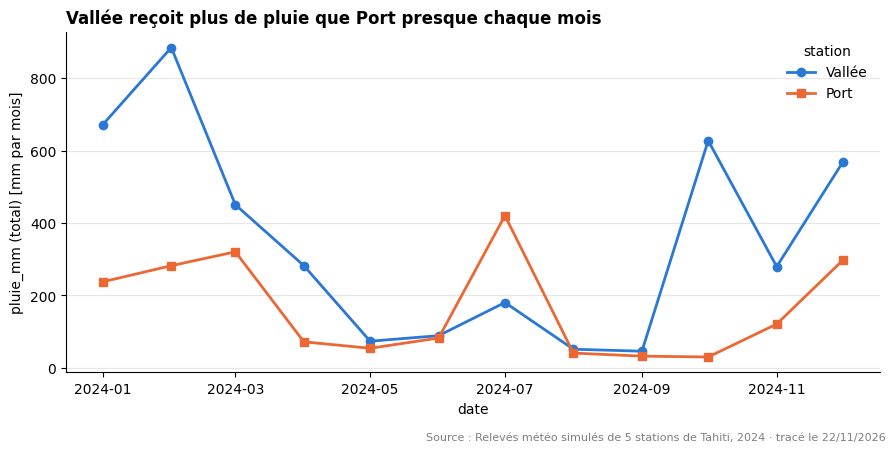

In [13]:
courbe(df, "date", "pluie_mm", par="station", garder=["Vallée", "Port"], pas="M", agg="sum",
       titre="Vallée reçoit plus de pluie que Port presque chaque mois", unite="mm par mois", source=SOURCE)

**Résultat attendu**

Deux courbes mensuelles : `Vallée` monte jusqu'à environ 880 mm en février, `Port` reste en dessous presque tous les mois, sauf un pic en juillet.

**Questions**
- (a) le verbe, (b) la fonction, (d) le message. Que se passe-t-il à Port en juillet ? Repensez aux valeurs « étonnantes » du TP 1.

**Réponse.** (a) **suivre** dans le temps ; (b) **`courbe`**, avec `par="station"`, `garder=["Vallée", "Port"]` et `agg="sum"` ; (d) « Vallée reçoit plus de pluie que Port presque chaque mois », surtout de décembre à mars. En juillet, `Port` dépasse `Vallée` : ce pic vient des deux journées de 180 et 210 mm, les valeurs « étonnantes » gardées au TP 1. Un graphique fait ressortir les valeurs à revérifier.

### Q3 · Les jours de pluie sont-ils plutôt faibles ou forts ?

> **Je prédis → J'exécute → Je constate**

Quoi ? la pluie **des jours où il pleut** · selon quoi ? sa répartition · où et quand ? toutes les stations, 2024. Pour ne garder que les jours de pluie, utilisez `df[df["pluie_mm"] > 0]` à la place de `df`.

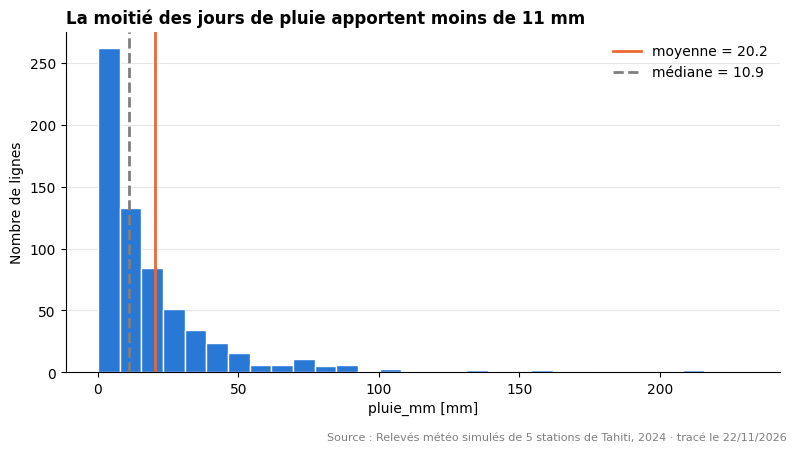

In [14]:
histogramme(df[df["pluie_mm"] > 0], "pluie_mm", bins=30,
            titre="La moitié des jours de pluie apportent moins de 11 mm", unite="mm", source=SOURCE)

**Résultat attendu**

Un histogramme très asymétrique : la plupart des jours de pluie sont sous 20 mm, avec une longue traîne. Moyenne 20,2 mm, médiane 10,9 mm.

**Questions**
- (a) le verbe, (b) la fonction, (d) le message. Pourquoi la moyenne est-elle plus grande que la médiane ?

**Réponse.** (a) voir la **répartition** ; (b) **`histogramme`**, sur les seuls jours de pluie ; (d) « La moitié des jours de pluie apportent moins de 11 mm ». La moyenne (20,2 mm) est presque le double de la médiane (10,9) : quelques journées très fortes, jusqu'à 231 mm, tirent la moyenne vers le haut.

### Q4 · Pleut-il davantage quand on monte en altitude ?

> **Je prédis → J'exécute → Je constate**

Quoi ? la pluie moyenne par jour · selon quoi ? l'altitude · où et quand ? les 5 stations, 2024. Avec un point par jour, le nuage est illisible : il faut **un point par station**.

> **Ce que vous dites à l'assistant**
>
> « J'ai un DataFrame pandas `df` avec les colonnes `station`, `altitude_m` et `pluie_mm`. Écris-moi une ligne qui crée `par_station` : une ligne par station, avec l'altitude et la pluie moyenne par jour, et `station` gardée comme colonne. »

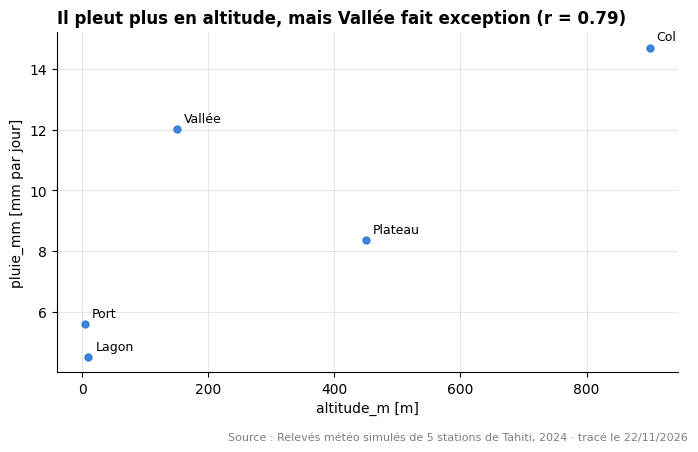

In [15]:
par_station = df.groupby("station", as_index=False)[["altitude_m", "pluie_mm"]].mean()
nuage(par_station, "altitude_m", "pluie_mm", etiquettes="station",
      titre="Il pleut plus en altitude, mais Vallée fait exception", unite=("m", "mm par jour"), source=SOURCE)

**Résultat attendu**

Cinq points étiquetés, un par station, avec « (r = 0.79) » dans le titre : `Vallée` est bien au-dessus de la tendance.

**Questions**
- (a) le verbe, (b) la fonction, (d) le message. Le lien est-il parfait ? Quelle station fait exception, et pourquoi le r d'un point par station est-il bien plus fort que celui d'un point par jour (0,12 au TP 2) ?

**Réponse.** (a) chercher un **lien** ; (b) **`nuage`**, sur un tableau d'une ligne par station (`par_station`), avec `etiquettes="station"` ; (d) « Il pleut plus en altitude, mais Vallée fait exception ». Le lien n'est pas parfait : `Vallée`, à 150 m, reçoit plus que `Plateau`, à 450 m, sans doute parce qu'elle est exposée aux vents humides. Avec un point par station, r = 0,79 : on compare des moyennes, et les énormes variations d'un jour à l'autre, avec tous leurs zéros, disparaissent. Prudence : seulement 5 points, et `Col` n'a que la saison des pluies.

### Q5 · La pluie varie-t-elle plus à une station qu'à une autre ?

> **Je prédis → J'exécute → Je constate**

Quoi ? la pluie des jours de pluie · selon quoi ? la station, en détail · où et quand ? 5 stations, 2024.

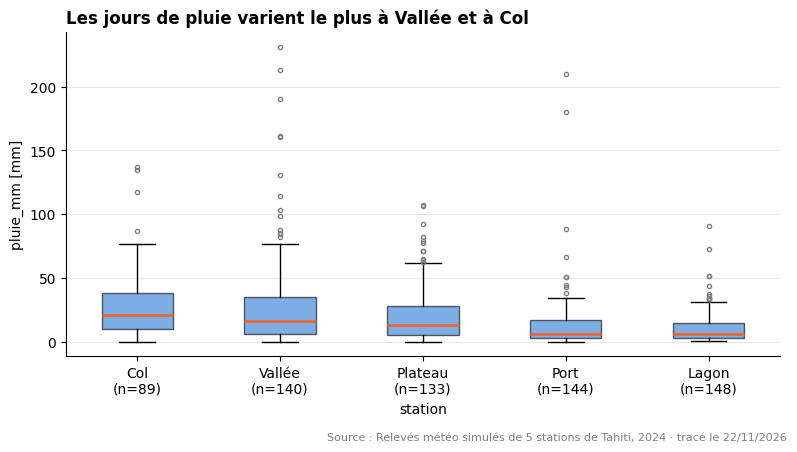

In [16]:
boite(df[df["pluie_mm"] > 0], "station", "pluie_mm",
      titre="Les jours de pluie varient le plus à Vallée et à Col", unite="mm", source=SOURCE)

**Résultat attendu**

Cinq boîtes : les plus hautes et les plus larges sont celles de `Col` et de `Vallée`. `Port` et `Lagon` ont des boîtes basses et serrées, avec quelques points très hauts.

**Questions**
- (a) le verbe, (b) la fonction, (d) le message.

**Réponse.** (a) **comparer des groupes en détail** ; (b) **`boite`**, sur les jours de pluie ; (d) « Les jours de pluie varient le plus à Vallée et à Col » : leurs boîtes sont les plus hautes et les plus larges, avec un écart interquartile d'environ 28 mm, contre 12 mm à `Lagon`.

### Q6 · La différence entre saison des pluies et saison fraîche est-elle la même à toutes les stations ?

> **Je prédis → J'exécute → Je constate**

Quoi ? la pluie moyenne par jour · selon quoi ? la station **et** la saison · où et quand ? 5 stations, 2024.

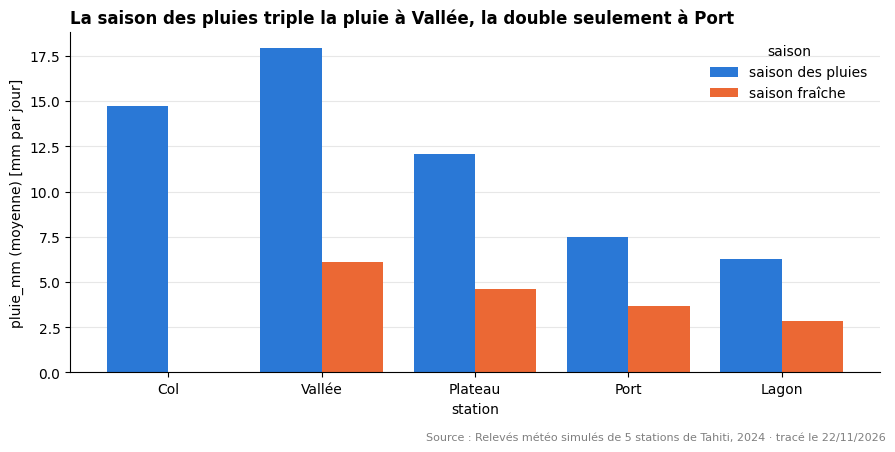

In [17]:
barres_croisees(df, "station", "saison", "pluie_mm", agg="mean",
                titre="La saison des pluies triple la pluie à Vallée, la double seulement à Port",
                unite="mm par jour", source=SOURCE)

**Résultat attendu**

Des barres groupées : la saison des pluies (bleu) dépasse partout la saison fraîche (orange), de 17,9 contre 6,1 mm par jour à `Vallée` jusqu'à 7,5 contre 3,7 à `Port`. `Col` n'a qu'une barre.

**Questions**
- (a) le verbe, (b) la fonction, (d) le message. Pourquoi `Col` n'a-t-il qu'une barre ?

**Réponse.** (a) **croiser** deux catégories, la station et la saison ; (b) **`barres_croisees`** ; (d) « La saison des pluies triple la pluie à Vallée (17,9 contre 6,1 mm par jour), la double seulement à Port (7,5 contre 3,7) ». La différence n'est donc pas la même partout. `Col` n'a qu'une barre : il n'a aucun relevé en saison fraîche.

### Q7 (bonus) · Un de vos constats du TP 2

Reprenez un de vos cinq constats chiffrés du TP 2, et tracez-le.

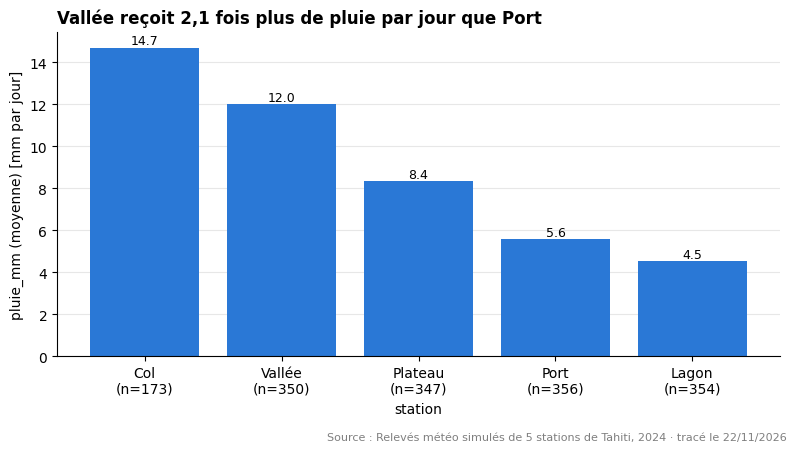

In [18]:
barres(df, "station", "pluie_mm", agg="mean",
       titre="Vallée reçoit 2,1 fois plus de pluie par jour que Port", unite="mm par jour", source=SOURCE)

**Questions**
- Votre constat, (a) le verbe, (b) la fonction, (d) le message.

**Réponse.** Constat repris : « Vallée reçoit 2,1 fois plus de pluie par jour que Port ». (a) **comparer** des catégories ; (b) **`barres`**, avec `agg="mean"` ; (d) le constat lui-même devient le titre. La moyenne par jour rend `Col` un peu plus comparable, mais sa barre ne parle que de la saison des pluies.

### Q8 · Le piège de l'axe coupé

> **Je prédis → J'exécute → Je constate**

Le graphique de Q1, deux fois : d'abord avec un axe qui démarre à 1 500 mm, juste sous la plus petite barre, puis à 0. La fonction prévient quand l'axe est coupé.

ATTENTION : l'axe commence à 1500 et pas à 0. Les différences entre barres paraissent bien plus grandes qu'elles ne sont.


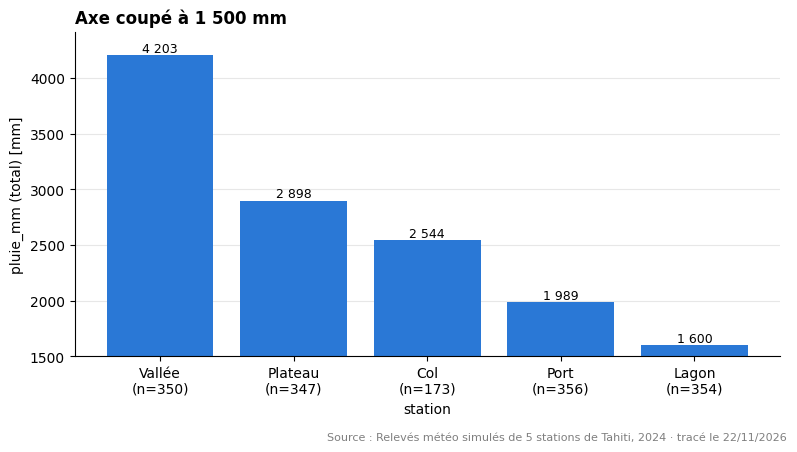

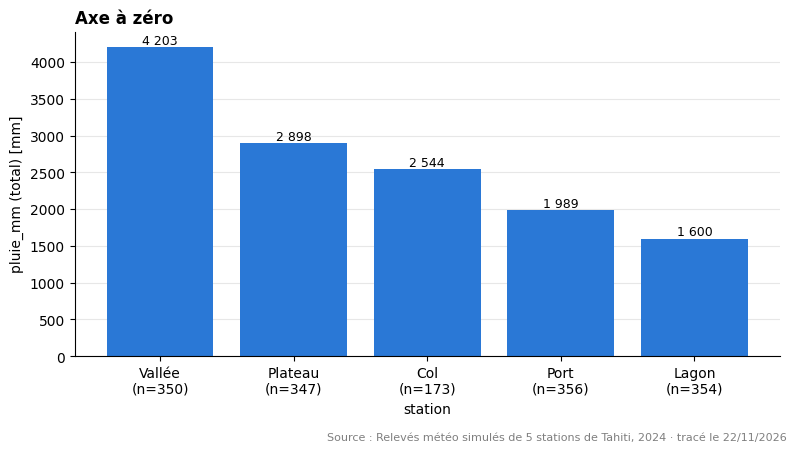

In [19]:
barres(df, "station", "pluie_mm", agg="sum", debut_axe=1500,
       titre="Axe coupé à 1 500 mm", unite="mm", source=SOURCE)
barres(df, "station", "pluie_mm", agg="sum",
       titre="Axe à zéro", unite="mm", source=SOURCE)

**Résultat attendu**

```text
ATTENTION : l'axe commence à 1500 et pas à 0. Les différences entre barres paraissent bien plus grandes qu'elles ne sont.
```

puis deux graphiques : le premier fait paraître la barre de `Lagon` minuscule ; le second montre les vraies proportions.

**Questions**
- Sur le premier graphique, combien de fois la barre de Vallée paraît-elle plus haute que celle de Lagon ? Et sur le second ? Quel est le vrai rapport ?
- Pourquoi les barres doivent-elles partir de zéro, alors qu'une courbe peut avoir un axe qui ne part pas de zéro ?

**Réponse.** Avec l'axe coupé à 1 500 mm, la barre de `Vallée` (4 203) paraît environ **27 fois** plus haute que celle de `Lagon` (1 600), car on ne voit que ce qui dépasse 1 500 : 2 703 contre 100. Avec l'axe à zéro, elle paraît **2,6 fois** plus haute : c'est le vrai rapport. Une barre se lit par sa longueur ; si elle ne part pas de zéro, sa longueur ment. Une courbe se lit par sa forme et ses variations, pas par sa hauteur depuis zéro : on peut zoomer, à condition de le dire.

## Ce qu'il faut rendre

Un notebook Colab par binôme, avec les deux noms en haut. Il doit contenir :
- toutes les cellules, **exécutées**, avec leurs graphiques visibles ;
- pour chaque question, le verbe, la fonction et le message, dans les cellules « Votre réponse ».

## Glossaire

| Mot | En une phrase |
|---|---|
| **Question solide** | Trois ingrédients : quoi ? selon quoi ? où et quand ? |
| **Le verbe choisit le graphique** | Comparer → barres, suivre → courbe, répartition → histogramme, lien → nuage, groupes en détail → boîte, part d'un tout → camembert. |
| **Titre-message** | Un titre qui dit ce qu'il faut retenir, pas seulement ce qui est tracé. |
| **Unité** | Toujours écrite sur l'axe : mm, °C, m… |
| **Source et date** | D'où viennent les données, et quand le graphique a été fait. |
| **Axe coupé** | Un axe qui ne part pas de zéro : il grossit les différences entre barres. |
| **Médiane** | La valeur qui coupe les données en deux moitiés, moins sensible aux extrêmes que la moyenne. |
| **Boîte à moustaches** | La médiane, les quartiles et les valeurs extrêmes d'un groupe, en un dessin. |